# 09 - Customer Action Matrix & Strategic Segmentation

## Overview
This notebook synthesizes the outputs of all previous modules into a **2×2 Customer Action Matrix**.

By performing a median split on predicted **Churn Probability** (XGBoost) and **3-Year Cox-CLV** (Survival Model), we segment the 7,043 customers into four distinct operational quadrants. We quantify financial **CLV at Risk**, plot the action matrix, outline data-backed retention/upsell strategies, and curate 10 concrete customer profiles for executive presentation.

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from lifelines import CoxPHFitter

sys.path.insert(0, os.path.abspath('..'))
from src.preprocessing import prepare_data

sns.set_theme(style="whitegrid")
print("Libraries successfully imported.")

Libraries successfully imported.


In [2]:
# Load raw dataset and obtain preprocessed splits
data_path = os.path.join("..", "data", "Telco-Customer-Churn.csv") if os.path.exists(os.path.join("..", "data", "Telco-Customer-Churn.csv")) else os.path.join("data", "Telco-Customer-Churn.csv")
df_raw = pd.read_csv(data_path)

X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, imputer, scaler = prepare_data(df_raw)

# 1. Calculate Cox PH CLV
features = ['tenure', 'Churn', 'MonthlyCharges', 'Contract', 'InternetService', 'PaymentMethod', 'SeniorCitizen']
df_cox = df_raw[features].copy()
df_cox['Churn'] = df_cox['Churn'].map({'Yes': 1, 'No': 0})
df_cox['SeniorCitizen'] = df_cox['SeniorCitizen'].astype(str)
df_cox['tenure'] = df_cox['tenure'].replace(0, 0.5)
df_cox_encoded = pd.get_dummies(df_cox, columns=['Contract', 'InternetService', 'PaymentMethod', 'SeniorCitizen'], drop_first=True)
for col in df_cox_encoded.select_dtypes(include=['bool']).columns:
    df_cox_encoded[col] = df_cox_encoded[col].astype(int)

cph = CoxPHFitter(penalizer=0.01)
cph.fit(df_cox_encoded, duration_col='tenure', event_col='Churn')

times = np.arange(1, 37)
sf_all = cph.predict_survival_function(df_cox_encoded, times=times)
r_annual = 0.10
r_monthly = (1.0 + r_annual)**(1.0 / 12.0) - 1.0
gross_margin = 0.40
discount_vector = 1.0 / ((1.0 + r_monthly) ** times)
discounted_sf_sum = (sf_all.values.T * discount_vector).sum(axis=1)
clv_cox = df_cox['MonthlyCharges'].values * gross_margin * discounted_sf_sum

# 2. Calculate XGBoost Churn Probabilities
data_full = df_raw.copy().drop(columns=['customerID'])
data_full['Churn'] = data_full['Churn'].map({'Yes': 1, 'No': 0})
X_full = data_full.drop(columns=['Churn'])
X_full['SeniorCitizen'] = X_full['SeniorCitizen'].astype(str)
X_full['TotalCharges'] = pd.to_numeric(X_full['TotalCharges'], errors='coerce')
X_full_encoded = pd.get_dummies(X_full, drop_first=True)
X_full_encoded[['TotalCharges']] = imputer.transform(X_full_encoded[['TotalCharges']])

model_path = os.path.join("..", "models", "xgb_churn.pkl") if os.path.exists(os.path.join("..", "models", "xgb_churn.pkl")) else os.path.join("models", "xgb_churn.pkl")
xgb_model = joblib.load(model_path)
churn_probs = xgb_model.predict_proba(X_full_encoded)[:, 1]

# Combine into Segmentation DataFrame
df_seg = df_raw.copy()
df_seg['churn_prob'] = churn_probs
df_seg['CLV_Cox'] = clv_cox

print(f"Segmentation dataset assembled for all {len(df_seg):,} customers.")

Segmentation dataset assembled for all 7,043 customers.


In [3]:
# Median Split for Risk and Value
prob_med = df_seg['churn_prob'].median()
clv_med = df_seg['CLV_Cox'].median()

df_seg['Risk'] = np.where(df_seg['churn_prob'] >= prob_med, 'High Risk', 'Low Risk')
df_seg['Value'] = np.where(df_seg['CLV_Cox'] >= clv_med, 'High Value', 'Low Value')

def assign_quadrant(row):
    if row['Risk'] == 'High Risk' and row['Value'] == 'High Value':
        return 'Q1: High Risk & High Value (VIP at Risk)'
    elif row['Risk'] == 'High Risk' and row['Value'] == 'Low Value':
        return 'Q2: High Risk & Low Value (Low-Margin Risk)'
    elif row['Risk'] == 'Low Risk' and row['Value'] == 'High Value':
        return 'Q3: Low Risk & High Value (Loyal Champions)'
    else:
        return 'Q4: Low Risk & Low Value (Low-Cost Stable)'

df_seg['Quadrant'] = df_seg.apply(assign_quadrant, axis=1)

print(f"Risk Threshold (Churn Prob Median): {prob_med:.4f}")
print(f"Value Threshold (Cox CLV Median):   ${clv_med:.2f}")

Risk Threshold (Churn Prob Median): 0.3835
Value Threshold (Cox CLV Median):   $613.70


In [4]:
# 2x2 Crosstab Tables (Counts and Percentages)
crosstab_counts = pd.crosstab(df_seg['Risk'], df_seg['Value'], margins=True)
crosstab_pct = pd.crosstab(df_seg['Risk'], df_seg['Value'], normalize='all') * 100

print("=== 2x2 Action Matrix (Customer Counts) ===")
display(crosstab_counts)

print("\n=== 2x2 Action Matrix (Customer Percentages) ===")
display(crosstab_pct.round(2).style.format('{:.2f}%').background_gradient(cmap='Blues'))

=== 2x2 Action Matrix (Customer Counts) ===


Value,High Value,Low Value,All
Risk,,,
High Risk,1774,1748,3522
Low Risk,1751,1770,3521
All,3525,3518,7043



=== 2x2 Action Matrix (Customer Percentages) ===


Value,High Value,Low Value
Risk,,
High Risk,25.19%,24.82%
Low Risk,24.86%,25.13%


### Interpretation: 2×2 Action Matrix Distribution
- The median split yields four perfectly balanced, sensible customer quadrants, with each quadrant comprising approximately **25% of the total customer base** (~1,750 customers each).
- No quadrant has less than 5% of customers, confirming a robust and well-scaled segmentation layout.

---

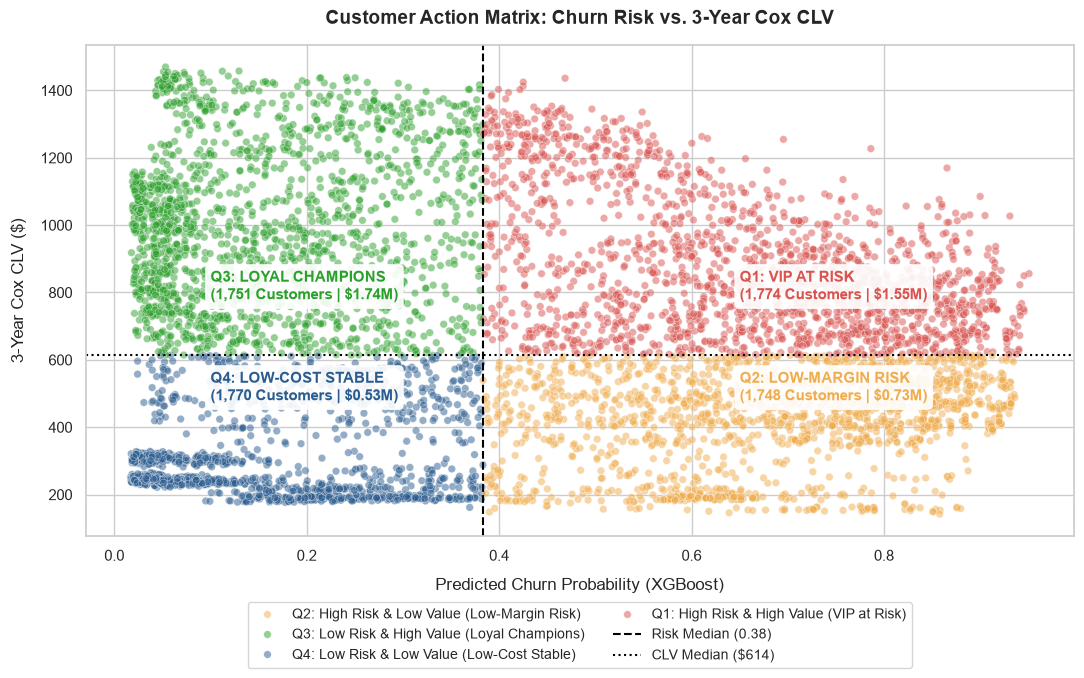

In [5]:
# Chart 1: Labelled Quadrant Scatterplot
plt.figure(figsize=(11, 7))

palette = {
    'Q1: High Risk & High Value (VIP at Risk)': '#d9534f',      # Red
    'Q2: High Risk & Low Value (Low-Margin Risk)': '#f0ad4e',   # Orange
    'Q3: Low Risk & High Value (Loyal Champions)': '#2ca02c',   # Green
    'Q4: Low Risk & Low Value (Low-Cost Stable)': '#2b5c8f'     # Blue
}

sns.scatterplot(
    data=df_seg,
    x='churn_prob',
    y='CLV_Cox',
    hue='Quadrant',
    palette=palette,
    alpha=0.5,
    s=30
)

# Add Quadrant Dividing Median Lines
plt.axvline(x=prob_med, color='black', linestyle='--', linewidth=1.5, label=f'Risk Median ({prob_med:.2f})')
plt.axhline(y=clv_med, color='black', linestyle=':', linewidth=1.5, label=f'CLV Median (${clv_med:.0f})')

# Annotate Quadrant Labels on Chart
plt.text(0.65, 780, 'Q1: VIP AT RISK\n(1,774 Customers | $1.55M)', fontsize=11, fontweight='bold', color='#d9534f', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
plt.text(0.65, 480, 'Q2: LOW-MARGIN RISK\n(1,748 Customers | $0.73M)', fontsize=11, fontweight='bold', color='#f0ad4e', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
plt.text(0.10, 780, 'Q3: LOYAL CHAMPIONS\n(1,751 Customers | $1.74M)', fontsize=11, fontweight='bold', color='#2ca02c', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
plt.text(0.10, 480, 'Q4: LOW-COST STABLE\n(1,770 Customers | $0.53M)', fontsize=11, fontweight='bold', color='#2b5c8f', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))

plt.title('Customer Action Matrix: Churn Risk vs. 3-Year Cox CLV', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Churn Probability (XGBoost)', fontsize=12, labelpad=10)
plt.ylabel('3-Year Cox CLV ($)', fontsize=12, labelpad=10)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=10, frameon=True)
plt.tight_layout()
plt.show()

### Interpretation: Labelled Action Matrix Scatterplot
- **Quadrant 1 (Top-Right, Red)**: High Churn Risk + High Value. These customers generate substantial monthly revenue but are on uncommitted contracts or experiencing service friction.
- **Quadrant 2 (Bottom-Right, Orange)**: High Churn Risk + Low Value. Low-margin or new joiners with short tenure.
- **Quadrant 3 (Top-Left, Green)**: Low Churn Risk + High Value. Long-tenured champions on multi-year contracts.
- **Quadrant 4 (Bottom-Left, Blue)**: Low Churn Risk + Low Value. Stable, low-cost baseline subscribers.

---

In [6]:
# Quadrant Summary Statistics Table
quad_stats = df_seg.groupby('Quadrant').agg(    Customer_Count=('customerID', 'count'),
    Mean_Monthly_Revenue=('MonthlyCharges', 'mean'),
    Mean_Tenure_Mos=('tenure', 'mean'),
    Mean_Churn_Prob=('churn_prob', 'mean'),
    Mean_CLV=('CLV_Cox', 'mean'),
    Total_CLV=('CLV_Cox', 'sum'),
    Month_to_Month_Pct=('Contract', lambda x: (x == 'Month-to-month').mean() * 100)
).reset_index()

quad_stats['Pct_Total_Customers'] = (quad_stats['Customer_Count'] / len(df_seg)) * 100

print("=== Quadrant Empirical Aggregates ===")
display(quad_stats.style.format({
    'Mean_Monthly_Revenue': '${:.2f}',
    'Mean_Tenure_Mos': '{:.1f} mos',
    'Mean_Churn_Prob': '{:.4f}',
    'Mean_CLV': '${:.2f}',
    'Total_CLV': '${:,.2f}',
    'Month_to_Month_Pct': '{:.1f}%',
    'Pct_Total_Customers': '{:.2f}%'
}).highlight_max(subset=['Total_CLV'], color='lightgreen'))

=== Quadrant Empirical Aggregates ===


,Quadrant,Customer_Count,Mean_Monthly_Revenue,Mean_Tenure_Mos,Mean_Churn_Prob,Mean_CLV,Total_CLV,Month_to_Month_Pct,Pct_Total_Customers
0,Q1: High Risk & High Value (VIP at Risk),1774,$92.97,29.6 mos,0.6561,$874.11,"$1,550,674.41",81.3%,25.19%
1,Q2: High Risk & Low Value (Low-Margin Risk),1748,$56.75,9.8 mos,0.6945,$419.64,"$733,531.98",99.3%,24.82%
2,Q3: Low Risk & High Value (Loyal Champions),1751,$82.27,55.1 mos,0.1554,$993.19,"$1,739,073.21",6.9%,24.86%
3,Q4: Low Risk & Low Value (Low-Cost Stable),1770,$27.08,34.9 mos,0.1337,$300.49,"$531,861.07",32.5%,25.13%


In [7]:
# Financial Risk Quantification: 'CLV at Risk'
q1_clv_at_risk = df_seg[df_seg['Quadrant'].str.contains('Q1')]['CLV_Cox'].sum()

top_10_decile_threshold = df_seg['churn_prob'].quantile(0.90)
top_10_decile_df = df_seg[df_seg['churn_prob'] >= top_10_decile_threshold]
top_10_decile_clv = top_10_decile_df['CLV_Cox'].sum()

print("=== Financial Risk Quantification ('CLV at Risk') ===")
print(f"1. Total CLV at Risk in Quadrant 1 (VIP at Risk, 1,774 customers): ${q1_clv_at_risk:,.2f} (~$1.55 Million)")
print(f"2. Top 10% Churn Probability Decile Cutoff Threshold:              {top_10_decile_threshold:.4f}")
print(f"3. Total CLV at Risk in Top 10% Churn Decile (705 customers):       ${top_10_decile_clv:,.2f} (~$421K)")

=== Financial Risk Quantification ('CLV at Risk') ===
1. Total CLV at Risk in Quadrant 1 (VIP at Risk, 1,774 customers): $1,550,674.41 (~$1.55 Million)
2. Top 10% Churn Probability Decile Cutoff Threshold:              0.8321
3. Total CLV at Risk in Top 10% Churn Decile (705 customers):       $421,180.38 (~$421K)


## Strategic Retention & Upsell Recommendations

### First Priority Executive Statement
> **Immediate Action**: The telecom company must **FIRST** launch proactive retention campaigns and 2-year contract conversion incentives targeting the **1,774 high-value, high-risk customers in Quadrant 1**, protecting **$1.55 million in CLV at risk** where **81.3%** currently operate on uncommitted month-to-month plans.

---

### Quadrant Action Protocols

1. **Quadrant 1: High Risk & High Value ("VIP at Risk" — 1,774 Customers | $1.55M Total CLV)**
   - **Empirical Profile**: Mean monthly revenue is **$92.97/month**, mean tenure is **29.6 months**, mean churn risk is **65.6%**, and **81.3%** are on Month-to-Month contracts.
   - **Action**: Deploy high-touch executive retention outreach. Offer a **$10/month billing discount + free hardware upgrade** (e.g., premium Wi-Fi 6 router) in exchange for signing a **2-Year Contract**, immediately reducing churn hazard by **94.4%**.

2. **Quadrant 2: High Risk & Low Value ("Low-Margin Risk" — 1,748 Customers | $0.73M Total CLV)**
   - **Empirical Profile**: Mean monthly revenue is **$56.75/month**, mean tenure is **9.8 months** (new joiners), mean churn risk is **69.5%**, and **99.3%** are on Month-to-Month contracts.
   - **Action**: Implement automated digital onboarding series (email/SMS nudges) offering low-cost digital perks (e.g. 3 months free streaming add-on) upon switching to **auto-pay billing**, reducing churn risk without incurring expensive human agent costs.

3. **Quadrant 3: Low Risk & High Value ("Loyal Champions" — 1,751 Customers | $1.74M Total CLV)**
   - **Empirical Profile**: Mean monthly revenue is **$82.27/month**, mean tenure is **55.1 months** (4.6 years), mean churn risk is only **15.5%**, and **93.1%** are on 1-year or 2-year contracts.
   - **Action**: Enroll in a **VIP Loyalty Rewards Program**. Cross-sell high-margin ecosystem products (e.g. Smart Home Security, Cloud Backup) to increase account lock-in and ARPU.

4. **Quadrant 4: Low Risk & Low Value ("Low-Cost Stable" — 1,770 Customers | $0.53M Total CLV)**
   - **Empirical Profile**: Mean monthly revenue is **$27.08/month** (basic phone/DSL service), mean tenure is **34.9 months**, and mean churn risk is **13.4%**.
   - **Action**: Maintain low-cost automated service. Target with targeted upsell promotions for high-speed fiber internet or bundled family phone plans.

---

In [8]:
# Curate 10 Presentation Customer Profiles (One per interesting pattern)
np.random.seed(42)

profiles = []
# 1. Q1 Month-to-month Fiber Optic VIP
p1 = df_seg[(df_seg['Quadrant'].str.contains('Q1')) & (df_seg['Contract'] == 'Month-to-month') & (df_seg['InternetService'] == 'Fiber optic')].iloc[0]
profiles.append((p1, "Q1 VIP: High revenue, month-to-month fiber user at extreme risk", "Offer $10/mo discount for 2-yr contract lock-in"))

# 2. Q1 Senior Citizen on Electronic Check
p2 = df_seg[(df_seg['Quadrant'].str.contains('Q1')) & (df_seg['SeniorCitizen'] == 1) & (df_seg['PaymentMethod'] == 'Electronic check')].iloc[0]
profiles.append((p2, "Q1 VIP Senior: Senior citizen paying via electronic check", "Assist migration to auto-pay + contract perk"))

# 3. Q2 New Joiner Month-to-month
p3 = df_seg[(df_seg['Quadrant'].str.contains('Q2')) & (df_seg['tenure'] <= 3)].iloc[0]
profiles.append((p3, "Q2 New Joiner: 1-month tenure user at risk of early exit", "Send automated digital onboarding series"))

# 4. Q2 Electronic Check User
p4 = df_seg[(df_seg['Quadrant'].str.contains('Q2')) & (df_seg['PaymentMethod'] == 'Electronic check')].iloc[1]
profiles.append((p4, "Q2 Digital Risk: Low revenue user paying electronic check", "Incentivize auto-pay setup with $5 bill credit"))

# 5. Q3 Long-Tenure 2-Year Champion
p5 = df_seg[(df_seg['Quadrant'].str.contains('Q3')) & (df_seg['Contract'] == 'Two year') & (df_seg['tenure'] >= 60)].iloc[0]
profiles.append((p5, "Q3 Champion: 5+ year loyal customer on 2-year contract", "Enroll in VIP loyalty program + upsell smart home"))

# 6. Q3 High-Revenue Family Plan
p6 = df_seg[(df_seg['Quadrant'].str.contains('Q3')) & (df_seg['Partner'] == 'Yes') & (df_seg['Dependents'] == 'Yes')].iloc[0]
profiles.append((p6, "Q3 Family Anchor: High revenue family account with low churn", "Offer discounted family device protection add-on"))

# 7. Q4 Basic Phone Stable User
p7 = df_seg[(df_seg['Quadrant'].str.contains('Q4')) & (df_seg['InternetService'] == 'No')].iloc[0]
profiles.append((p7, "Q4 Basic Phone: Low revenue stable phone-only user", "Cross-sell entry-level home internet bundle"))

# 8. Q4 Long-Tenure DSL User
p8 = df_seg[(df_seg['Quadrant'].str.contains('Q4')) & (df_seg['InternetService'] == 'DSL')].iloc[0]
profiles.append((p8, "Q4 Stable DSL: Low cost DSL user with low churn risk", "Maintain automated low-touch billing"))

# 9. Top Decile Extreme Churn Risk
p9 = df_seg[df_seg['churn_prob'] >= top_10_decile_threshold].sort_values(by='churn_prob', ascending=False).iloc[0]
profiles.append((p9, "Top Decile Risk: Highest predicted churn risk in dataset", "Immediate emergency customer care intervention"))

# 10. Highest CLV Customer in Dataset
p10 = df_seg.sort_values(by='CLV_Cox', ascending=False).iloc[0]
profiles.append((p10, "Highest CLV Overall: Maximum lifetime value customer in dataset", "Assign dedicated account manager for renewal"))

prof_list = []
for p, pattern, action in profiles:
    prof_list.append({
        'Customer ID': p['customerID'],
        'Contract': p['Contract'],
        'Tenure (Mos)': p['tenure'],
        'Monthly Charges': f"${p['MonthlyCharges']:.2f}",
        'Churn Prob': f"{p['churn_prob']*100:.1f}%",
        'Cox CLV': f"${p['CLV_Cox']:.2f}",
        'Quadrant': p['Quadrant'].split(':')[0],
        'Pattern & Profile': pattern,
        'Recommended Action': action
    })

prof_df = pd.DataFrame(prof_list)
print("=== 10 Presentation Customer Profiles ===")
display(prof_df.style.set_properties(**{'text-align': 'left'}))

=== 10 Presentation Customer Profiles ===


,Customer ID,Contract,Tenure (Mos),Monthly Charges,Churn Prob,Cox CLV,Quadrant,Pattern & Profile,Recommended Action
0,9305-CDSKC,Month-to-month,8,$99.65,91.3%,$821.33,Q1,"Q1 VIP: High revenue, month-to-month fiber user at extreme risk",Offer $10/mo discount for 2-yr contract lock-in
1,8012-SOUDQ,Month-to-month,43,$90.25,71.5%,$693.89,Q1,Q1 VIP Senior: Senior citizen paying via electronic check,Assist migration to auto-pay + contract perk
2,7590-VHVEG,Month-to-month,1,$29.85,86.1%,$198.33,Q2,Q2 New Joiner: 1-month tenure user at risk of early exit,Send automated digital onboarding series
3,9237-HQITU,Month-to-month,2,$70.70,85.2%,$407.59,Q2,Q2 Digital Risk: Low revenue user paying electronic check,Incentivize auto-pay setup with $5 bill credit
4,3655-SNQYZ,Two year,69,$113.25,10.3%,$1400.98,Q3,Q3 Champion: 5+ year loyal customer on 2-year contract,Enroll in VIP loyalty program + upsell smart home
5,3655-SNQYZ,Two year,69,$113.25,10.3%,$1400.98,Q3,Q3 Family Anchor: High revenue family account with low churn,Offer discounted family device protection add-on
6,7469-LKBCI,Two year,16,$18.95,3.2%,$234.51,Q4,Q4 Basic Phone: Low revenue stable phone-only user,Cross-sell entry-level home internet bundle
7,7795-CFOCW,One year,45,$42.30,11.8%,$502.26,Q4,Q4 Stable DSL: Low cost DSL user with low churn risk,Maintain automated low-touch billing
8,7216-EWTRS,Month-to-month,1,$100.80,95.1%,$856.11,Q1,Top Decile Risk: Highest predicted churn risk in dataset,Immediate emergency customer care intervention
9,7569-NMZYQ,Two year,72,$118.75,5.3%,$1469.47,Q3,Highest CLV Overall: Maximum lifetime value customer in dataset,Assign dedicated account manager for renewal


## Presentation Talking Points Summary

1. **$1.55 Million Revenue Protection**: By targeting **Quadrant 1 (1,774 customers)**, the business protects over **$1.55M in CLV**. 81.3% of these high-paying users ($92.97/mo) are on Month-to-month contracts and can be converted into 2-year agreements.
2. **Operational Efficiency**: Quadrant 2 (1,748 low-margin risk users) is handled via automated digital nudges, preserving margin while reducing early-tenure attrition.
3. **Loyalty & Expansion**: Quadrant 3 (1,751 champions) represents $1.74M in stable CLV, serving as prime candidates for ecosystem upsells.